In [1]:
import pandas as pd
import numpy as np

In [2]:
df = pd.read_csv('ecommerce_sales_analytics_5000.csv')
df.head()

,order_id,order_date,customer_id,product_category,region,quantity,unit_price,discount,payment_method,delivery_days,customer_rating,revenue
0,10001,1/1/2022,1102,Beauty,South,7,373.65,0.28,Wallet,10,4.7,1883.20
1,10002,1/2/2022,1435,Clothing,South,7,47.74,0.09,Card,6,3.9,304.10
2,10003,1/3/2022,1860,Beauty,East,3,311.28,0.31,COD,6,2.5,644.35
3,10004,1/4/2022,1270,Electronics,West,5,524.47,0.02,Wallet,6,1.6,2569.90
4,10005,1/5/2022,1106,Clothing,West,5,139.87,0.33,Wallet,4,4.9,468.56


In [3]:
df.shape

(5000, 12)

In [4]:
df.dtypes

order_id              int64
order_date              str
customer_id           int64
product_category        str
region                  str
quantity              int64
unit_price          float64
discount            float64
payment_method          str
delivery_days         int64
customer_rating     float64
revenue             float64
dtype: object

In [5]:
df.duplicated().sum()

np.int64(0)

In [6]:
df.isna().sum()

order_id            0
order_date          0
customer_id         0
product_category    0
region              0
quantity            0
unit_price          0
discount            0
payment_method      0
delivery_days       0
customer_rating     0
revenue             0
dtype: int64

In [7]:
df.drop(columns=['order_id', 'customer_id']).mean(numeric_only=True)

quantity              4.044800
unit_price          308.418774
discount              0.179984
delivery_days         6.118800
customer_rating       2.973980
revenue            1021.955148
dtype: float64

In [8]:
df.drop(columns=['order_id', 'customer_id']).median(numeric_only=True)

quantity             4.00
unit_price         309.89
discount             0.18
delivery_days        6.00
customer_rating      3.00
revenue            796.65
dtype: float64

In [9]:
df.drop(columns=['order_date']).select_dtypes(include=['object']).mode()

C:\Users\abc\AppData\Local\Temp\ipykernel_15200\2274236429.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.drop(columns=['order_date']).select_dtypes(include=['object']).mode()


,product_category,region,payment_method
0,Electronics,West,Card


In [10]:
df.drop(columns=['order_id', 'customer_id']).std(numeric_only=True)

quantity             2.020398
unit_price         169.259369
discount             0.101404
delivery_days        3.153264
customer_rating      1.157722
revenue            825.584219
dtype: float64

In [11]:
df.dtypes

order_id              int64
order_date              str
customer_id           int64
product_category        str
region                  str
quantity              int64
unit_price          float64
discount            float64
payment_method          str
delivery_days         int64
customer_rating     float64
revenue             float64
dtype: object

In [12]:
df['order_date'] = pd.to_datetime(df['order_date'])
df.dtypes

order_id                     int64
order_date          datetime64[us]
customer_id                  int64
product_category               str
region                         str
quantity                     int64
unit_price                 float64
discount                   float64
payment_method                 str
delivery_days                int64
customer_rating            float64
revenue                    float64
dtype: object

In [32]:
monthly_sales = np.zeros(12)
for i in range(1, 13):
    monthly_sales[i-1] = df[df['order_date'].dt.month == i]['revenue'].sum()
monthly_sales

array([426374.92, 413890.24, 425050.52, 398715.16, 479772.55, 442941.58,
       440570.72, 460874.78, 402368.11, 407873.12, 410657.88, 400686.16])

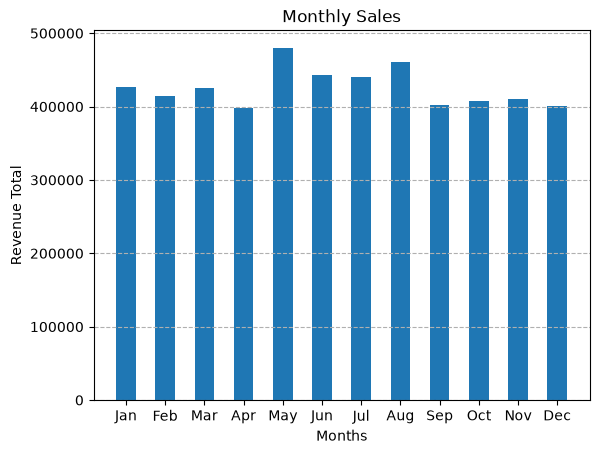

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

months = [
    'Jan', 'Feb', 'Mar',
    'Apr', 'May', 'Jun',
    'Jul', 'Aug', 'Sep',
    'Oct', 'Nov', 'Dec'
]
plt.bar(months, monthly_sales, width=0.5)
plt.title('Monthly Sales')
plt.xlabel('Months')
plt.ylabel('Revenue Total')
plt.grid(axis='y', linestyle='--')
plt.show()

### May had the peak revenue gain

In [15]:
quarter_sales = np.zeros(4)
for i in range(1, 13):
    quarter_sales[(i-1)//3] += df[df['order_date'].dt.month == i]['revenue'].sum()
quarter_sales

array([1265315.68, 1321429.29, 1303813.61, 1219217.16])

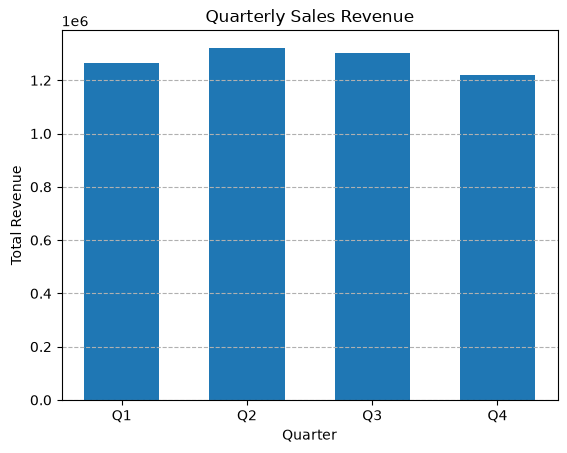

In [16]:
quarters = ['Q1', 'Q2', 'Q3', 'Q4']

plt.bar(quarters, quarter_sales, width=0.6)
plt.title('Quarterly Sales Revenue')
plt.xlabel('Quarter')
plt.ylabel('Total Revenue')
plt.grid(axis='y', linestyle='--')
plt.show() 

### quarter 2 and 3 contributed slightly more to the business than other quarters.

In [17]:
df.columns

Index(['order_id', 'order_date', 'customer_id', 'product_category', 'region',
       'quantity', 'unit_price', 'discount', 'payment_method', 'delivery_days',
       'customer_rating', 'revenue'],
      dtype='str')

In [18]:
region = df['region']
payment_mode = df['payment_method']

In [19]:
region_counts = df['region'].value_counts()

payment_counts = df['payment_method'].value_counts()

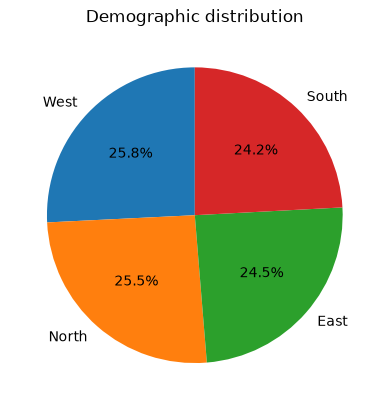

In [20]:
plt.pie(region_counts.values, labels=region_counts.index, autopct='%1.1f%%', startangle=90)
plt.title('Demographic distribution')
plt.show()

### nearly equal contribution of all 4 states in business

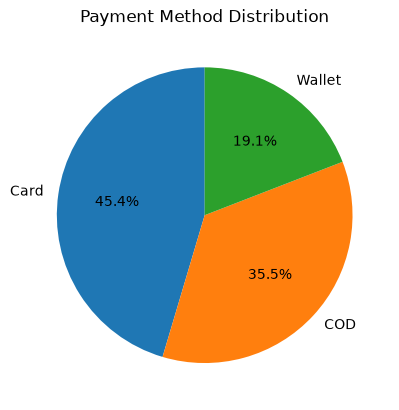

In [21]:
plt.pie(payment_counts.values, labels=payment_counts.index, autopct='%1.1f%%', startangle=90)
plt.title('Payment Method Distribution')
plt.show()

### customers are using card payment method too often

In [22]:
df.head()

,order_id,order_date,customer_id,product_category,region,quantity,unit_price,discount,payment_method,delivery_days,customer_rating,revenue
0,10001,2022-01-01,1102,Beauty,South,7,373.65,0.28,Wallet,10,4.7,1883.20
1,10002,2022-01-02,1435,Clothing,South,7,47.74,0.09,Card,6,3.9,304.10
2,10003,2022-01-03,1860,Beauty,East,3,311.28,0.31,COD,6,2.5,644.35
3,10004,2022-01-04,1270,Electronics,West,5,524.47,0.02,Wallet,6,1.6,2569.90
4,10005,2022-01-05,1106,Clothing,West,5,139.87,0.33,Wallet,4,4.9,468.56


In [23]:
df['product_category'].value_counts()

product_category
Electronics    1777
Clothing       1531
Home            969
Beauty          723
Name: count, dtype: int64

In [24]:
revenue = df.groupby('product_category')['revenue'].sum().reset_index()
revenue.columns = ['product_category', 'total_revenue']
revenue

,product_category,total_revenue
0,Beauty,765860.88
1,Clothing,1531931.72
2,Electronics,1829899.22
3,Home,982083.92


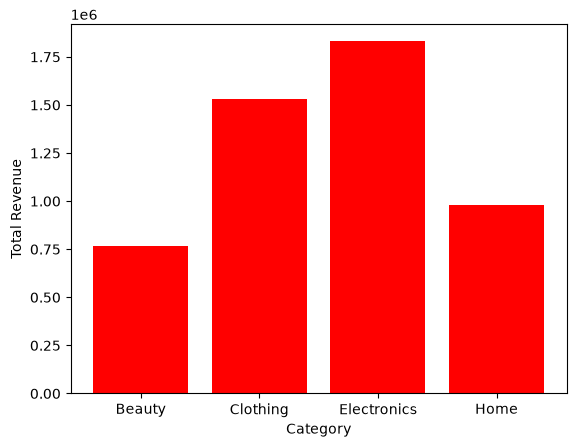

In [25]:
plt.bar(revenue['product_category'], revenue['total_revenue'], color='red')
plt.xlabel('Category')
plt.ylabel('Total Revenue')
plt.show()

### Electronics and clothing are the most bought products category of all

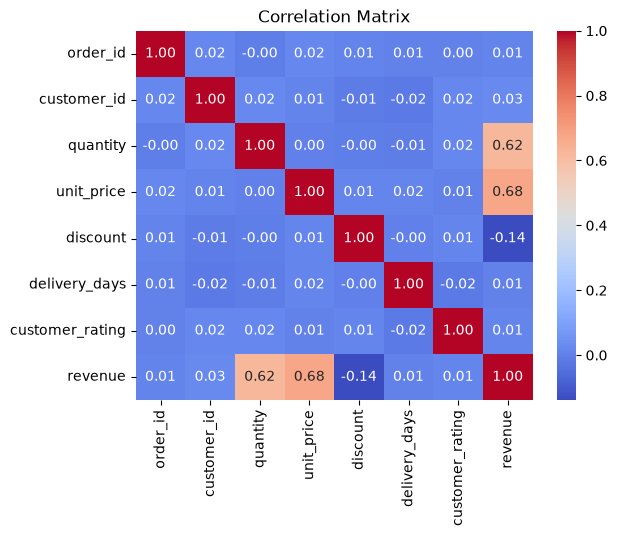

In [26]:
corr = df.select_dtypes(include=['number']).corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix')
plt.show()

### quantity, revenue and unit price, revenue have mild positive correlation while discount and revenue have slightly negative correlation



In [27]:
df.head()

,order_id,order_date,customer_id,product_category,region,quantity,unit_price,discount,payment_method,delivery_days,customer_rating,revenue
0,10001,2022-01-01,1102,Beauty,South,7,373.65,0.28,Wallet,10,4.7,1883.20
1,10002,2022-01-02,1435,Clothing,South,7,47.74,0.09,Card,6,3.9,304.10
2,10003,2022-01-03,1860,Beauty,East,3,311.28,0.31,COD,6,2.5,644.35
3,10004,2022-01-04,1270,Electronics,West,5,524.47,0.02,Wallet,6,1.6,2569.90
4,10005,2022-01-05,1106,Clothing,West,5,139.87,0.33,Wallet,4,4.9,468.56


In [28]:
region_method = pd.crosstab(df['region'], df['payment_method'])
region_method

payment_method,COD,Card,Wallet
region,,,
East,461,548,218
North,429,601,246
South,438,526,244
West,446,595,248


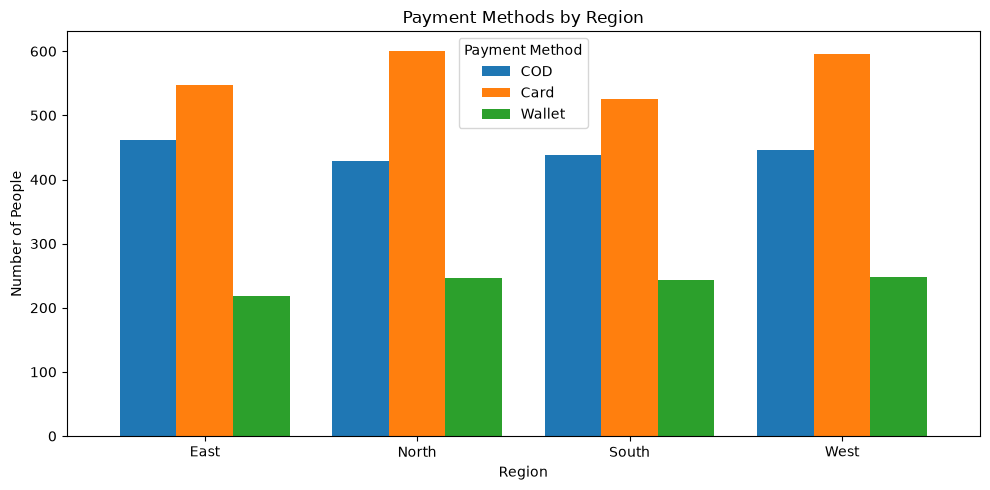

In [29]:
region_method.plot(kind='bar', figsize=(10, 5), width=0.8)

plt.title('Payment Methods by Region')
plt.xlabel('Region')
plt.ylabel('Number of People')
plt.xticks(rotation=0)
plt.legend(title='Payment Method')
plt.tight_layout()
plt.show()

## Across all the 4 states, card is the most used mode of payment


In [30]:
region_product = pd.crosstab(df['region'], df['product_category'])
region_product

product_category,Beauty,Clothing,Electronics,Home
region,,,,
East,165,395,418,249
North,194,378,462,242
South,172,365,455,216
West,192,393,442,262


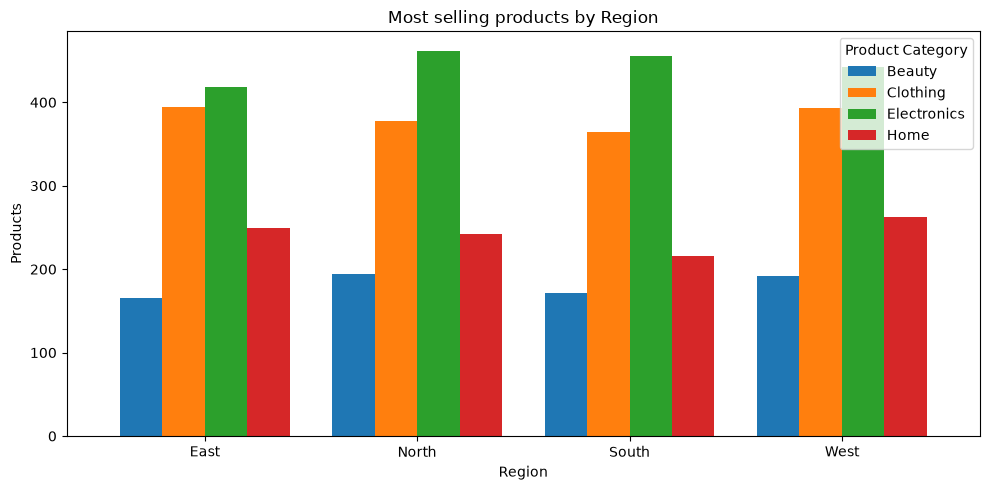

In [31]:
region_product.plot(kind='bar', figsize=(10, 5), width=0.8)

plt.title('Most selling products by Region')
plt.xlabel('Region')
plt.ylabel('Products')
plt.xticks(rotation=0)
plt.legend(title='Product Category')
plt.tight_layout()
plt.show()

### Across the 4 states, clothing and electronics are most purchased  with north and sourth slightly profiting electronics more

# Recommendation

1) Beauty products needs the most attention, by improving advertisements, trusts, make available at affordable costs by introducing seasional, festival discount
2) Promote wallet mode of payment as this would also benefit merchants operating on those modes and thus, improving loyalty to merchants too.
3) Revenue had mild-strong correlation with unit_price and very low-negative correation with discount thus, unit price and discount schemes must be reformed to prevent significant crash-out in future like it happened in april and september.